In [1]:
import rawpy
import sys
import os
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
import numpy as np
import cv2
import imageio
import tifffile
import seaborn as sns

import colour
# 1. Load the standard chart data
cc24_data = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
# 2. Convert the reference data from xyY color space to XYZ tristimulus values (t)
xyY_values = np.array(list(cc24_data.data.values()))

# 3. Convert the xyY array directly into CIE XYZ tristimulus values (t)
t_XYZ = colour.xyY_to_XYZ(list(xyY_values))

helperFolder = Path("../helper")
if str(helperFolder.resolve()) not in sys.path:
    sys.path.insert(0, str(helperFolder.resolve()))

import utils
import psu_imaging as psu
importlib.reload(utils)
importlib.reload(psu)

baseFilePath = 'images/IMG_0'
startingImage = 278
options = ['overhead','led','incandescent','outside1','outside2']
imagePaths = dict((option, []) for option in options)
for j in range(len(options)):
    for i in range(0,4,1):
        fileNumber = startingImage + i + j*4
        imagePaths[options[j]].append(f"{baseFilePath}{fileNumber}.DNG")
print(imagePaths)

{'overhead': ['images/IMG_0278.DNG', 'images/IMG_0279.DNG', 'images/IMG_0280.DNG', 'images/IMG_0281.DNG'], 'led': ['images/IMG_0282.DNG', 'images/IMG_0283.DNG', 'images/IMG_0284.DNG', 'images/IMG_0285.DNG'], 'incandescent': ['images/IMG_0286.DNG', 'images/IMG_0287.DNG', 'images/IMG_0288.DNG', 'images/IMG_0289.DNG'], 'outside1': ['images/IMG_0290.DNG', 'images/IMG_0291.DNG', 'images/IMG_0292.DNG', 'images/IMG_0293.DNG'], 'outside2': ['images/IMG_0294.DNG', 'images/IMG_0295.DNG', 'images/IMG_0296.DNG', 'images/IMG_0297.DNG']}


## Part 1

### D1

In [82]:
importlib.reload(utils)
for pathGroup in imagePaths:
    for path in imagePaths[pathGroup]:
        response = utils.lens_id(path)
        # print(f"Round: {pathGroup}, Path: {path[7:15]}, Lens Model: {response['lensModel']}, ISO: {response['iso']}, Exposure Time: {response['exposureTimeSeconds']:.4f}")
        print(
            f"Round: {pathGroup:<14} "
            f"Path: {path[7:15]:<10} "
            f"Lens Model: {response['lensModel']:<36} "
            f"ISO: {response['iso']:>5} "
            f"Exposure Time: {response['exposureTimeSeconds']:.4f}"
        )

Round: overhead       Path: IMG_0278   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: overhead       Path: IMG_0279   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: overhead       Path: IMG_0280   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: overhead       Path: IMG_0281   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: led            Path: IMG_0282   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: led            Path: IMG_0283   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: led            Path: IMG_0284   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: led            Path: IMG_0285   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   400 Exposure Time: 0.0167
Round: incandescent   Path: IMG_

In [90]:
importlib.reload(utils)

def plot_histogram(hist, binCenters, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
    for ax in axes:
        sns.lineplot(
            x=binCenters,
            y=hist,
            ax=ax,
            estimator=None,
            errorbar=None,
        )
        ax.set_xlabel("RAW value")
        ax.set_ylabel("Pixel count")
    axes[0].set_title("Linear scale")
    axes[1].set_title("Logarithmic scale")
    axes[1].set_yscale("log", nonpositive="mask")
    sns.despine(fig=fig)
    fig.suptitle(f"White Level Histogram: {path[7:15]}")
    fig.tight_layout()
    plt.savefig('images/d1_histogram.png')
    plt.show()
    
    
    
    
    
sns.set_theme(style="whitegrid")

binMax = 4200
binMin = 3500
binRange = (binMin-0.5, binMax+0.5)
#plot the histogram of the first image 
for pathGroup in imagePaths:
    for path in imagePaths[pathGroup]:
        hist, binEdges = utils.white_level_histogram(path, binMin, binMax, binRange)

        binCenters = (binEdges[:-1] + binEdges[1:]) / 2
        # plot_histogram(hist, binCenters, path)
        rawMax = binCenters[np.argmax(hist)]
        rawMaxCount = hist[np.argmax(hist)]

        print(f'Image: {path[7:15]} Clipping Value: {rawMax} (Count: {rawMaxCount})')

Image: IMG_0278 Clipping Value: 4094.8492857142855 (Count: 9831)
Image: IMG_0279 Clipping Value: 4094.8492857142855 (Count: 6875)
Image: IMG_0280 Clipping Value: 4094.8492857142855 (Count: 3350)
Image: IMG_0281 Clipping Value: 4094.8492857142855 (Count: 67713)
Image: IMG_0282 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0283 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0284 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0285 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0286 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0287 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0288 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0289 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0290 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0291 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0292 Clipping Value: 3500.0007142857144 (Count: 0)
Image: IMG_0293 Clipping Value: 3500.0007142857144 (Count

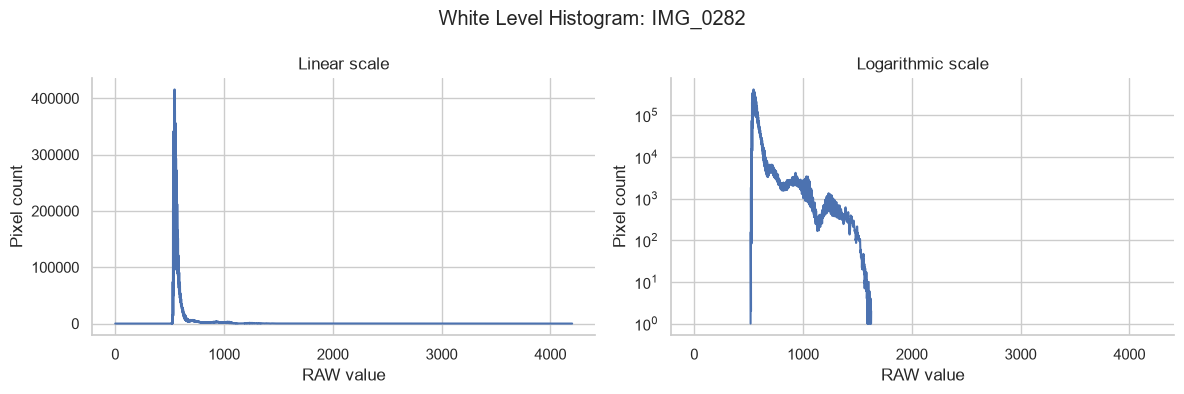

In [91]:
binMax = 4200
binMin = 0
binRange = (binMin-0.5, binMax+0.5)

hist, binEdges = utils.white_level_histogram(imagePaths["led"][0], binMin, binMax, binRange)
plot_histogram(hist, (binEdges[:-1] + binEdges[1:]) / 2, 'images/IMG_0282.DNG')



### D2

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.00224287599503..1.00004233428].


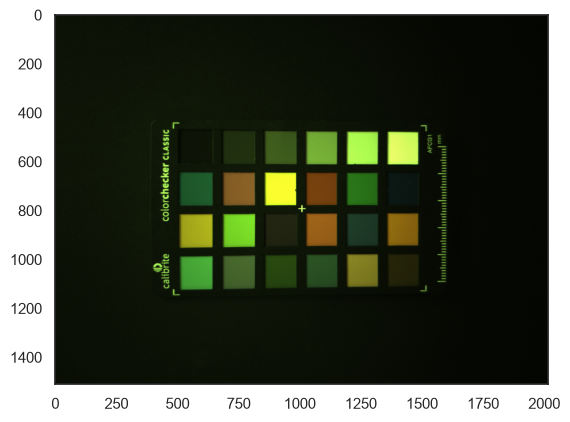

[[2 3]
 [1 0]]
['B', 'G', 'G', 'R']
4094.849


In [92]:
importlib.reload(utils)
sns.set_theme(style="white")

d2ImagePath = imagePaths["overhead"][0]

results = utils.raw_to_linear_rgb(d2ImagePath, 4094.849)

plt.imshow(results['stack'])
plt.savefig('images/d2.png')
plt.show()

print(results['pattern'])
print(results['colorNames'])
print(results['saturation'])

### D3

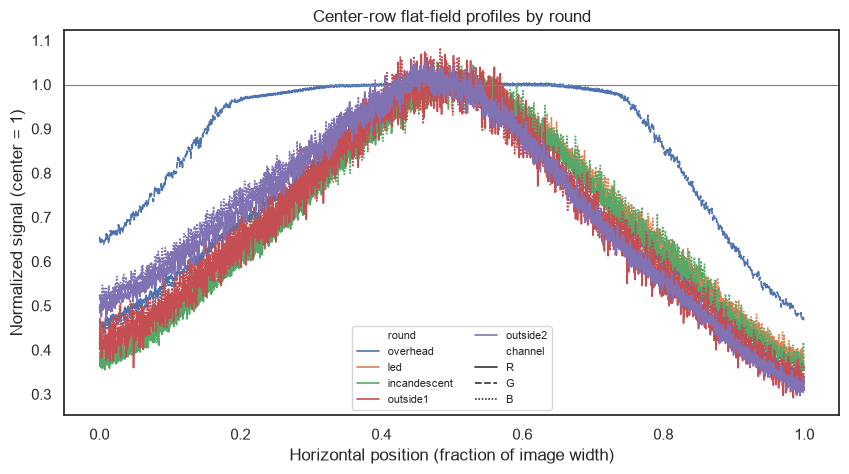

In [93]:
importlib.reload(utils)
flatWhiteDict = {}
for option in imagePaths:
    flatWhiteDict[option] = imagePaths[option][3]


d3LinearRgb = utils.raw_to_linear_rgb(flatWhiteDict['overhead'], 4094.84)["stack"]
d3Results = utils.flat_field_correct(d3LinearRgb, d3LinearRgb)

utils.plot_flat_field_profiles(flatWhiteDict, 4094.84)
plt.savefig('images/d3_dist.png')
plt.show()

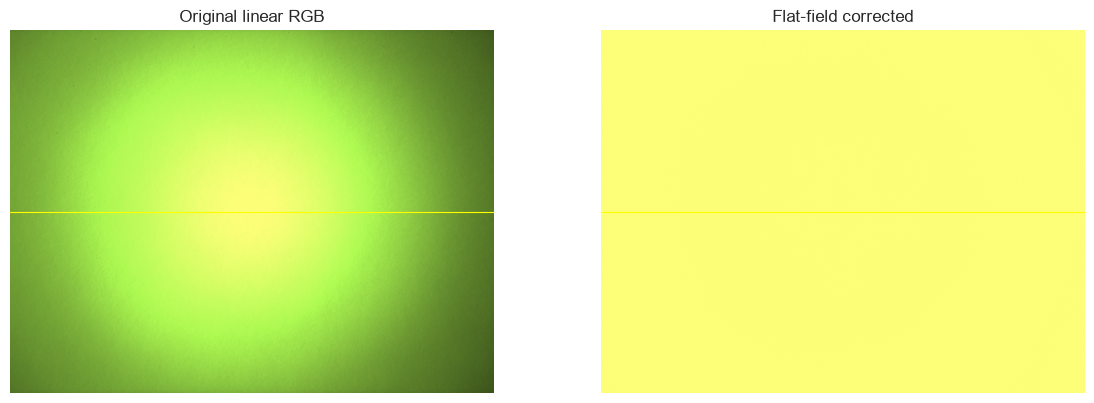

In [13]:
import pandas as pd

correctedRgb = d3Results["corrected"]
bandHeight = 16  # Rows averaged around the center to suppress noise
height, width = d3LinearRgb.shape[:2]
top = (height - bandHeight) // 2

profileFrames = []
for version, image in {"Original": d3LinearRgb, "Corrected": correctedRgb}.items():
    profile = np.nanmean(image[top:top + bandHeight], axis=0)
    for channelIndex, channelName in enumerate("RGB"):
        profileFrames.append(pd.DataFrame({
            "position": (np.arange(width) + 0.5) / width,
            "signal": profile[:, channelIndex],
            "channel": channelName,
            "version": version,
        }))
profileData = pd.concat(profileFrames, ignore_index=True)

sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(12, 8))
imageAxes = [fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)]


displayScale = np.nanpercentile(np.concatenate([d3LinearRgb, correctedRgb]), 99)  # Shared scale keeps brightness comparable
imagePanels = [("Original linear RGB", d3LinearRgb), ("Flat-field corrected", correctedRgb)]
for ax, (title, image) in zip(imageAxes, imagePanels):
    preview = np.clip(np.nan_to_num(image) / displayScale, 0, 1)
    ax.imshow(preview)
    ax.axhline(height / 2, color="yellow", linewidth=0.8)  # Profile row
    ax.set_title(title)
    ax.axis("off")

sns.despine(ax=profileAxis)
fig.tight_layout()
plt.savefig('images/d3_compare.png')
plt.show()

### D4

In [2]:
importlib.reload(utils)
# d2ImagePath = imagePaths["overhead"][0]

D4results = list()
patchResults = list() 

# 0-2 is overhead 
# 3-5 is LED
# 6-8 is incandescent
# 9-11 is outside1
# 12-14 is outside2



for pathGroup in imagePaths:
    for path in imagePaths[pathGroup]:
        D4results.append(utils.raw_to_linear_rgb(path, 4094.849))
        try:
            patchResults.append(utils.extract_colorchecker_means(D4results[-1]["stack"]))
            patchMeans = patchResults[-1]["meanRgb"]  # Shape: (24, 3), columns R, G, B
        except Exception as e:
            print(f"Failed to process {path}: {e}")
            continue


Failed to process images/IMG_0281.DNG: No 24-patch ColorChecker was detected
Failed to process images/IMG_0285.DNG: No 24-patch ColorChecker was detected
Failed to process images/IMG_0289.DNG: No 24-patch ColorChecker was detected
Failed to process images/IMG_0293.DNG: No 24-patch ColorChecker was detected
Failed to process images/IMG_0297.DNG: No 24-patch ColorChecker was detected


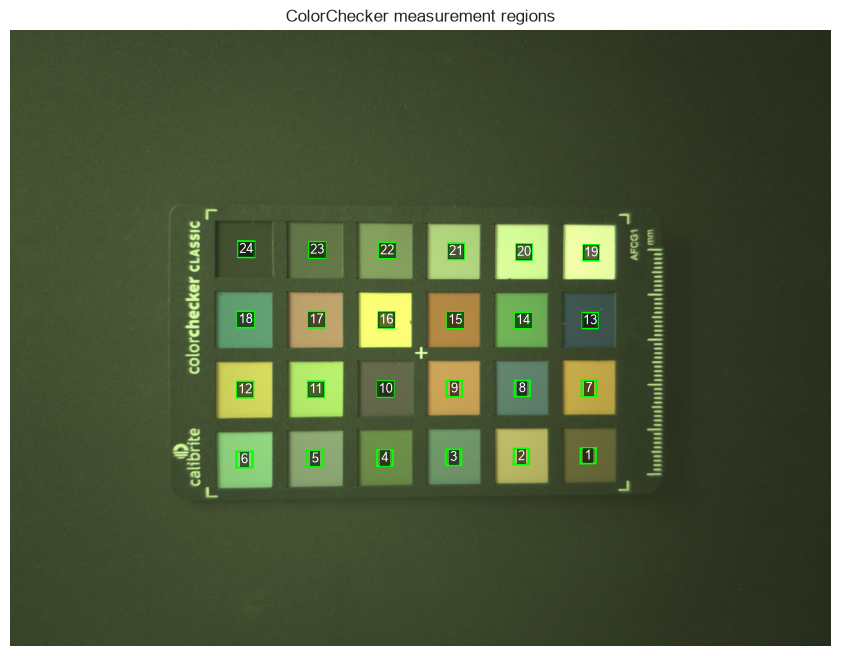

In [95]:
importlib.reload(utils)

ax = utils.plot_colorchecker_patches(
    D4results[0]["stack"],
    patchResults[0]["patchPolygons"],
)
plt.savefig("images/d4.png")
plt.show()

In [100]:
# for means in patchResults:
#     print(means["meanRgb"])
patchResults[0]["meanRgb"]

array([[ 0.13740006,  0.13681023,  0.03508312],
       [ 0.4952723 ,  0.48500104,  0.12845525],
       [ 0.1603953 ,  0.30612657,  0.13578061],
       [ 0.15219361,  0.27651478,  0.06284014],
       [ 0.268984  ,  0.39411194,  0.17324043],
       [ 0.27316196,  0.64683714,  0.208969  ],
       [ 0.53633791,  0.39624542,  0.05966677],
       [ 0.1153671 ,  0.2259201 ,  0.14949665],
       [ 0.60212779,  0.37686113,  0.09451173],
       [ 0.12801017,  0.14250718,  0.0675165 ],
       [ 0.47404271,  0.85179752,  0.14939341],
       [ 0.65592908,  0.67269163,  0.10571185],
       [ 0.0445433 ,  0.08887614,  0.07438115],
       [ 0.16004135,  0.44296026,  0.09308489],
       [ 0.46231046,  0.25408444,  0.05522811],
       [ 0.98456092,  0.99562236,  0.18165786],
       [ 0.52761675,  0.37478772,  0.14836397],
       [ 0.11785773,  0.34932186,  0.1674898 ],
       [ 0.86065957,  0.98614947,  0.381538  ],
       [ 0.6842552 ,  0.98868649,  0.31667157],
       [ 0.45632486,  0.68016873,  0.213

## Part 2

In [3]:
cameraRgb = patchResults[0]["meanRgb"]  # (24, 3)
referenceXYZ = np.asarray(t_XYZ)

rgbToXyz, _, rank, _ = np.linalg.lstsq(cameraRgb, referenceXYZ, rcond=None)
if rank != 3:
    raise ValueError("Camera RGB measurements cannot determine a full-rank transform")

whiteReference = referenceXYZ[18]
whiteTestXYZ = cameraRgb[18] @ rgbToXyz

# Use the chart reference illuminant for BOTH conversions, not the default D65.
referenceWhite = cc24_data.illuminant
whiteReferenceLab = colour.XYZ_to_Lab(whiteReference, illuminant=referenceWhite)
whiteTestLab = colour.XYZ_to_Lab(whiteTestXYZ, illuminant=referenceWhite)

whiteDeltaE = float(
    colour.delta_E(whiteReferenceLab, whiteTestLab, method="CIE 2000")
)

print(f"Reference Lab: {whiteReferenceLab}")
print(f"Test Lab:      {whiteTestLab}")
print(f"CIEDE2000:     {whiteDeltaE:.4f}")
print(f"White Reference: {whiteReference}\nWhite Test: {whiteTestXYZ}\nError: {whiteReference - whiteTestXYZ}/whiteReference")

Reference Lab: [ 95.19  -1.03   2.93]
Test Lab:      [ 85.81318066  11.47012027  -9.69334045]
CIEDE2000:     18.4630
White Reference: [ 0.84369853  0.88069032  0.69367788]
White Test: [ 0.70440256  0.67614221  0.65534284]
Error: [ 0.13929597  0.20454811  0.03833504]/whiteReference


### D5

In [4]:
## Look at neutral patches and determine color gains via balacning realtives to green channel k
neutralMeans = [patch for i, patch in enumerate(patchResults[0]["meanRgb"]) if i >= 20 and i <= 24]

unclipped = neutralMeans[2]
k = np.divide(1, unclipped)

redGain = np.divide(k[0], k[1])
greenGain = 1
blueGain = np.divide(k[2], k[1])

colorGain = np.array([redGain, greenGain, blueGain])
print(colorGain)


[ 1.49182333  1.          3.0949099 ]


In [5]:
## multiple every row in patch by colorGain
colorCorrection = [patch * colorGain for patch in patchResults[0]["meanRgb"]]

for i, item in enumerate(colorCorrection):
    print(
        f"Patch Number {i+1:<3}"
        f":{item}")
    #f"Round: {pathGroup:<14} "

Patch Number 1  :[ 0.20497662  0.13681023  0.10857908]
Patch Number 2  :[ 0.73885877  0.48500104  0.39755743]
Patch Number 3  :[ 0.23928145  0.30612657  0.42022877]
Patch Number 4  :[ 0.22704597  0.27651478  0.19448457]
Patch Number 5  :[ 0.4012766   0.39411194  0.53616351]
Patch Number 6  :[ 0.40750938  0.64683714  0.64674023]
Patch Number 7  :[ 0.80012141  0.39624542  0.18466326]
Patch Number 8  :[ 0.17210733  0.2259201   0.46267867]
Patch Number 9  :[ 0.89826828  0.37686113  0.2925053 ]
Patch Number 10 :[ 0.19096856  0.14250718  0.20895748]
Patch Number 11 :[ 0.70718797  0.85179752  0.46235916]
Patch Number 12 :[ 0.97853031  0.67269163  0.32716865]
Patch Number 13 :[ 0.06645073  0.08887614  0.23020297]
Patch Number 14 :[ 0.23875342  0.44296026  0.28808935]
Patch Number 15 :[ 0.68968553  0.25408444  0.17092601]
Patch Number 16 :[ 1.46879095  0.99562236  0.56221471]
Patch Number 17 :[ 0.78711098  0.37478772  0.45917312]
Patch Number 18 :[ 0.17582291  0.34932186  0.51836585]
Patch Numb

### D6

In [6]:
importlib.reload(utils)
baseline = utils.srgb_baseline_color_error(
    patchResults[0]["meanRgb"], 
    np.asarray(t_XYZ), 
    cc24_data.illuminant, 
    whiteIndex = 22
)
print(f"Mean ΔE00: {baseline['meanDeltaE']:.2f}  Max: {baseline['maxDeltaE']:.2f} using CIEDE 2000")

Mean ΔE00: 10.50  Max: 19.71 using CIEDE 2000


### D7

In [8]:
importlib.reload(utils)
colorGainMatrix = np.diag(colorGain)
D7fit = utils.fit_color_correction_matrix(
    patchResults[0]["meanRgb"], np.asarray(t_XYZ), cc24_data.illuminant, colorGain=colorGain, operateOnAllValues=True
)
print("Color matrix (XYZ = M @ balancedRgb):\n", D7fit["colorMatrix"])
print("Excluded (clipped) patches:", np.flatnonzero(~D7fit["fitMask"]) + 1)
print(f"Mean ΔE00: {D7fit['meanDeltaE']:.2f}  Max: {D7fit['maxDeltaE']:.2f} using CIEDE 2000")


Color matrix (XYZ = M @ balancedRgb):
 [[ 0.32995541  0.04216986  0.20254458]
 [ 0.09244477  0.38451876  0.15095757]
 [-0.00569117 -0.3705942   0.87067149]]
Excluded (clipped) patches: []
Mean ΔE00: 7.76  Max: 18.46 using CIEDE 2000


### D8

In [9]:
fitMask = D7fit["fitMask"]  # Reuse D7's unclipped patches so both passes fit the same data
referenceXYZ = np.asarray(t_XYZ)

secondPass, _, rank, _ = np.linalg.lstsq(
    D7fit["testXYZ"][fitMask], referenceXYZ[fitMask], rcond=None
)
adjustmentMatrix = secondPass.T  # Column-vector form: xyz = adjustmentMatrix @ testXYZ
refinedXYZ = D7fit["testXYZ"] @ secondPass

_, _, refinedDeltaE = utils._chart_delta_e(referenceXYZ, refinedXYZ, cc24_data.illuminant)

print("Adjustment matrix (should be ~identity):\n", adjustmentMatrix)
print(f"Largest change from identity: {np.abs(adjustmentMatrix - np.eye(3)).max():.2e}")
print(f"Pass 1 mean ΔE00: {D7fit['meanDeltaE']:.4f}  max: {D7fit['maxDeltaE']:.4f}")
print(f"Pass 2 mean ΔE00: {refinedDeltaE[fitMask].mean():.4f}  max: {refinedDeltaE[fitMask].max():.4f}")

Adjustment matrix (should be ~identity):
 [[  1.00000000e+00  -9.10831184e-17  -3.49769527e-17]
 [  1.30454090e-15   1.00000000e+00   3.33066907e-16]
 [  1.21898696e-15  -7.77156117e-16   1.00000000e+00]]
Largest change from identity: 1.30e-15
Pass 1 mean ΔE00: 7.7624  max: 18.4630
Pass 2 mean ΔE00: 7.7624  max: 18.4630


Before: mean ΔE00 10.50, worst 19.71
    Patch 19 (white 9.5 (.05 D)): 19.71
    Patch 16 (yellow): 18.34
    Patch 6 (bluish green): 15.60
After: mean ΔE00 7.76, worst 18.46
    Patch 19 (white 9.5 (.05 D)): 18.46
    Patch 7 (orange): 12.02
    Patch 17 (magenta): 11.88


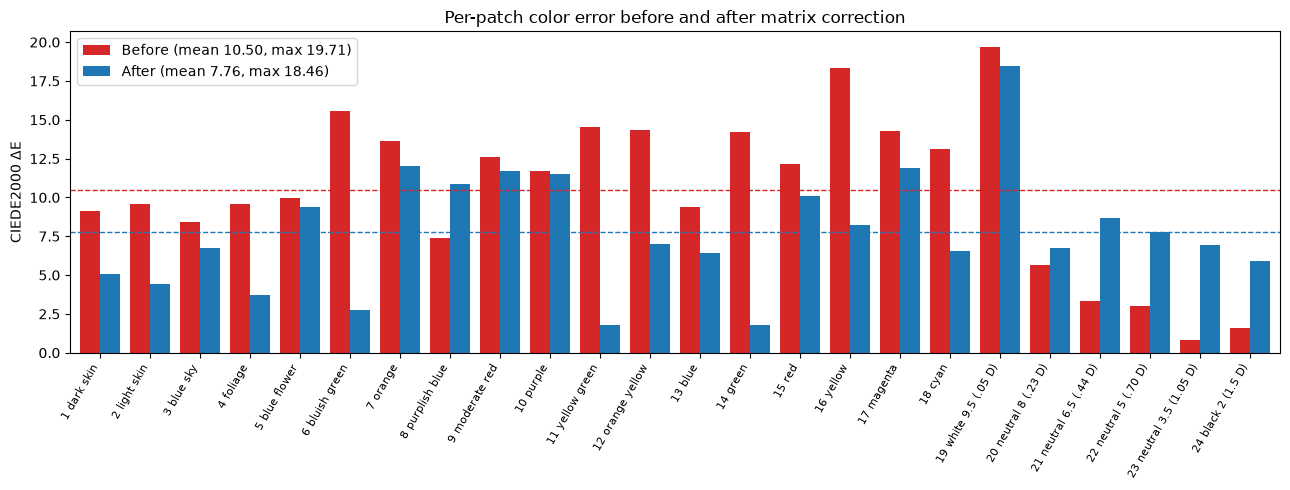

In [10]:
importlib.reload(utils)
patchNames = list(cc24_data.data.keys())  # Same order as t_XYZ and OpenCV's MCC24 model

ax, D8summary = utils.plot_delta_e_before_after(
    baseline["deltaE"],  # D6: white-balanced RGB treated as linear sRGB
    D7fit["deltaE"],  # D7: least-squares color matrix
    patchNames,
    statsMask=D7fit["fitMask"],  # Compare both over the same 21 unclipped patches
)
ax.figure.savefig("images/d8.png", dpi=200, bbox_inches="tight")

for label in ("before", "after"):
    stats = D8summary[label]
    print(f"{label.capitalize()}: mean ΔE00 {stats['meanDeltaE']:.2f}, worst {stats['maxDeltaE']:.2f}")
    for patchNumber, name, value in stats["worstPatches"]:
        print(f"    Patch {patchNumber} ({name}): {value:.2f}")

Before correction, the white-balanced camera RGB was treated as linear sRGB, which gave a mean CIEDE2000 error of 9.92 (worst 15.60) over the 21 unclipped patches. The camera's spectral sensitivities are not the sRGB primaries, so saturated colors were rendered badly desaturated. Bluish green had a* of −10 against a reference of −32, and yellow green had b* of 20 against 58. The neutral patches were already accurate (0.8–3.3), because white balance alone fixes grays.

The least-squares 3×3 matrix reduced the mean error to 4.13 and the worst to 7.22, restoring most of the missing chroma. The remaining worst patches are orange, purplish blue and purple. Their Lab values show orange is over-saturated in b* (69 vs. 57) and purplish blue and purple are short on a* (red). A linear 3×3 matrix can't reproduce the camera-to-observer mismatch exactly at the spectral extremes, so it trades error between them. The fit also minimizes XYZ error rather than ΔE, so dark and blue patches, where small XYZ errors become large perceptual errors, are weighted too lightly. As a result, the neutrals got slightly worse (up to 3.9) because the fit isn't forced to map gray exactly. Patches 16, 19 and 20 were saturated in green and were excluded from the fit and the statistics.

## Part 3

### D9

In [11]:
importlib.reload(utils)

def characterize_color(localPatchResults):
    ## D5 Look at neutral patches and determine color gains via balacning realtives to green channel k
    neutralMeans = [patch for i, patch in enumerate(localPatchResults["meanRgb"]) if i >= 20 and i <= 24]

    unclipped = neutralMeans[2]
    k = np.divide(1, unclipped)

    redGain = np.divide(k[0], k[1])
    greenGain = 1
    blueGain = np.divide(k[2], k[1])

    colorGain = np.array([redGain, greenGain, blueGain])
    # print(colorGain)
    
    ## multiple every row in patch by colorGain
    colorCorrection = [patch * colorGain for patch in localPatchResults["meanRgb"]]
    # for i, item in enumerate(colorCorrection):
        # print(f"Patch Number {i+1}: {item}")
    
    ##D6 
    baseline = utils.srgb_baseline_color_error(
        localPatchResults["meanRgb"], 
        np.asarray(t_XYZ), 
        cc24_data.illuminant, 
        whiteIndex = 22
    )
    # print(f"Mean ΔE00: {baseline['meanDeltaE']:.2f}  Max: {baseline['maxDeltaE']:.2f} using CIEDE 2000")
    
    ## D7 Fit color correction matrix with color gain applied
    colorGainMatrix = np.diag(colorGain)
    fit = utils.fit_color_correction_matrix(
        localPatchResults["meanRgb"], 
        np.asarray(t_XYZ), cc24_data.illuminant, 
        colorGain=colorGain,
        operateOnAllValues=True
    )
    # print("Color matrix (XYZ = M @ balancedRgb):\n", fit["colorMatrix"])
    # print("Excluded (clipped) patches:", np.flatnonzero(~fit["fitMask"]) + 1)
    # print(f"Mean ΔE00: {fit['meanDeltaE']:.2f}  Max: {fit['maxDeltaE']:.2f} using CIEDE 2000")
    
    results = {}
    results["beforeMeanDeltaE"] = baseline["meanDeltaE"]
    results["beforeMaxDeltaE"] = baseline["maxDeltaE"]
    results['meanDeltaE'] = fit['meanDeltaE']
    results['maxDeltaE'] = fit['maxDeltaE']
    results['colorMatrix'] = fit['colorMatrix']
    return results

def print_d9(resultsDictionary):
    print(f"Mean ΔE00: {resultsDictionary['meanDeltaE']:.2f}  Max: {resultsDictionary['maxDeltaE']:.2f} using CIEDE 2000")
    print("Color matrix (XYZ = M @ balancedRgb):\n", resultsDictionary['colorMatrix'])

# 0-2 is overhead 
# 3-5 is LED
# 6-8 is incandescent
# 9-11 is outside1
# 12-14 is outside2
# overheadResults = {'meanE': [], 'maxE': []}

# for i in range(3):
#     results = characterize_color(patchResults[i])
#     print(f"\nResults for overhead patch set {i}")
#     print_d9(results)
#     overheadResults['meanE'].append(results['meanDeltaE'])
#     overheadResults['maxE'].append(results['maxDeltaE']) 

overheadResults = {"beforeMeanE": [], "meanE": [], "maxE": []}

for i in range(3):
    results = characterize_color(patchResults[i])

    print(f"\nResults for overhead patch set {i}")
    print(
        f"Before: mean DE00 = {results['beforeMeanDeltaE']:.2f}, "
        f"worst = {results['beforeMaxDeltaE']:.2f}"
    )
    print_d9(results)

    overheadResults["beforeMeanE"].append(results["beforeMeanDeltaE"])
    overheadResults["meanE"].append(results["meanDeltaE"])
    overheadResults["maxE"].append(results["maxDeltaE"])

beforeMean = np.mean(overheadResults["beforeMeanE"])
beforeStd = np.std(overheadResults["beforeMeanE"])

print(f"\nBefore-matrix average DE00: {beforeMean:.3f}")
print(f"Standard deviation across captures: {beforeStd:.3f}")


Results for overhead patch set 0
Before: mean DE00 = 10.50, worst = 19.71
Mean ΔE00: 7.76  Max: 18.46 using CIEDE 2000
Color matrix (XYZ = M @ balancedRgb):
 [[ 0.32995541  0.04216986  0.20254458]
 [ 0.09244477  0.38451876  0.15095757]
 [-0.00569117 -0.3705942   0.87067149]]

Results for overhead patch set 1
Before: mean DE00 = 10.09, worst = 18.64
Mean ΔE00: 7.34  Max: 17.95 using CIEDE 2000
Color matrix (XYZ = M @ balancedRgb):
 [[ 0.33286436  0.06103879  0.20345414]
 [ 0.0872714   0.4086232   0.15308619]
 [-0.00965125 -0.35062852  0.87839934]]

Results for overhead patch set 2
Before: mean DE00 = 10.20, worst = 18.80
Mean ΔE00: 7.57  Max: 18.21 using CIEDE 2000
Color matrix (XYZ = M @ balancedRgb):
 [[ 0.33307844  0.04925857  0.21351969]
 [ 0.08725794  0.39755595  0.16175213]
 [-0.00760697 -0.36501331  0.88744359]]

Before-matrix average DE00: 10.261
Standard deviation across captures: 0.176


### D10

In [12]:
importlib.reload(utils)
print(
        f'Before Error: {np.mean(overheadResults["beforeMeanE"]):.3f}',
        f'+/- {np.std(overheadResults["beforeMeanE"]):.3f}')
print(
        f'Average Error: {np.mean(overheadResults["meanE"]):.3f}',
        f'+/- {np.std(overheadResults["meanE"]):.3f}')

##Update JSON with new results
utils.update_json_values("exercise4Results.json", {
    "delta_e_metric": "CIEDE2000",
    "colorchecker_reference_set": "ColorChecker24 - After November 2014",
        "delta_e_mean_before_ccm": [np.mean(overheadResults["beforeMeanE"]), np.std(overheadResults["beforeMeanE"])],
        "delta_e_mean_after_ccm": [np.mean(overheadResults['meanE']), np.std(overheadResults['meanE'])],
        "delta_e_worst_after_ccm": [np.max(overheadResults['maxE']), np.std(overheadResults['maxE'])]
})

Before Error: 10.261 +/- 0.176
Average Error: 7.558 +/- 0.174


## Part 4

### D11

In [13]:
print("Color matrix (XYZ = M @ balancedRgb):\n", D7fit["colorMatrix"])
print("Excluded (clipped) patches:", np.flatnonzero(~D7fit["fitMask"]) + 1)
print(f"Mean ΔE00: {D7fit['meanDeltaE']:.2f}  Max: {D7fit['maxDeltaE']:.2f} using CIEDE 2000")

# 3-5 is LED
def characterize_color_new_patch(localPatchResults, originalFit, *, neutralIndex=22, clipLevel=0.98):
    """Evaluate a new illuminant without refitting the D7 matrix.

    Refit relative white balance from neutralIndex (22 means patch 23), then
    scale all balanced RGB to match its published Y through the fixed matrix.
    References and Lab white point stay the same as D7. Both error summaries
    use common unclipped patches. Invalid data or an unusable neutral raises
    ValueError. Return gains, exposure scale, XYZ, errors, and comparison mask.
    """
    import colour

    meanRgb = np.asarray(localPatchResults["meanRgb"], dtype=float)
    referenceXYZ = np.asarray(t_XYZ, dtype=float)
    colorMatrix = np.asarray(originalFit["colorMatrix"], dtype=float)
    originalMask = np.asarray(originalFit["fitMask"], dtype=bool)
    originalDeltaE = np.asarray(originalFit["deltaE"], dtype=float)
    if meanRgb.ndim != 2 or meanRgb.shape[1] != 3 or meanRgb.shape != referenceXYZ.shape:
        raise ValueError("Measured RGB and reference XYZ must both be N x 3 arrays")
    if colorMatrix.shape != (3, 3):
        raise ValueError("The original color matrix must be 3 x 3")
    if originalMask.shape != (len(meanRgb),) or originalDeltaE.shape != (len(meanRgb),):
        raise ValueError("Original fit mask and errors must match the chart patch count")
    if not all(np.isfinite(values).all() for values in
               (meanRgb, referenceXYZ, colorMatrix, originalDeltaE)):
        raise ValueError("RGB, reference XYZ, matrix, and original errors must be finite")
    if not np.isfinite(clipLevel) or clipLevel <= 0:
        raise ValueError("clipLevel must be positive and finite")
    if (isinstance(neutralIndex, (bool, np.bool_))
            or not isinstance(neutralIndex, (int, np.integer))
            or not 0 <= neutralIndex < len(meanRgb)):
        raise ValueError("neutralIndex must be a valid zero-based patch index")

    unclippedMask = np.all(meanRgb < clipLevel, axis=1)
    neutralRgb = meanRgb[neutralIndex]
    if not unclippedMask[neutralIndex] or np.any(neutralRgb <= 0):
        raise ValueError("Choose a neutral patch with positive, unclipped RGB channels")
    if referenceXYZ[neutralIndex, 1] <= 0:
        raise ValueError("Reference neutral Y must be positive")

    colorGain = neutralRgb[1] / neutralRgb
    balancedRgb = meanRgb * colorGain
    unscaledXYZ = balancedRgb @ colorMatrix.T
    neutralY = unscaledXYZ[neutralIndex, 1]
    if not np.isfinite(neutralY) or neutralY <= 0:
        raise ValueError("The fixed matrix must predict a positive, finite neutral Y")
    exposureScale = referenceXYZ[neutralIndex, 1] / neutralY
    testXYZ = (balancedRgb * exposureScale) @ colorMatrix.T
    if not np.isfinite(testXYZ).all():
        raise ValueError("Scaled XYZ values must be finite")

    referenceLab = colour.XYZ_to_Lab(referenceXYZ, illuminant=cc24_data.illuminant)
    testLab = colour.XYZ_to_Lab(testXYZ, illuminant=cc24_data.illuminant)
    deltaE = np.asarray(colour.delta_E(referenceLab, testLab, method="CIE 2000"))
    if not np.isfinite(deltaE).all():
        raise ValueError("Computed color errors must be finite")
    comparisonMask = originalMask & unclippedMask
    if not comparisonMask.any():
        raise ValueError("No common unclipped patches are available for comparison")

    return {
        "meanDeltaE": float(deltaE[comparisonMask].mean()),
        "maxDeltaE": float(deltaE[comparisonMask].max()),
        "firstMeanDeltaE": float(originalDeltaE[comparisonMask].mean()),
        "firstMaxDeltaE": float(originalDeltaE[comparisonMask].max()),
        "colorMatrix": colorMatrix.copy(),
        "colorGain": colorGain,
        "exposureScale": float(exposureScale),
        "neutralIndex": neutralIndex,
        "testXYZ": testXYZ,
        "deltaE": deltaE,
        "unclippedMask": unclippedMask,
        "comparisonMask": comparisonMask,
    }


# Patch sets 3-5 are LED; compare set 3 with the original D7 fit.

D11Results = {'meanDeltaE': [], 'maxDeltaE': [], 'captures': []}
for i in range(3, 6):
    result = characterize_color_new_patch(patchResults[i], D7fit)
    D11Results['meanDeltaE'].append(result['meanDeltaE'])
    D11Results['maxDeltaE'].append(result['maxDeltaE'])
    D11Results['captures'].append(result)
print(f"{'Overhead Lights':<20} {D7fit['meanDeltaE']:12.2f} {D7fit['maxDeltaE']:12.2f}")
print(f"{'LED':<20} {np.mean(D11Results['meanDeltaE']):12.2f} {np.max(D11Results['maxDeltaE']):12.2f}")


Color matrix (XYZ = M @ balancedRgb):
 [[ 0.32995541  0.04216986  0.20254458]
 [ 0.09244477  0.38451876  0.15095757]
 [-0.00569117 -0.3705942   0.87067149]]
Excluded (clipped) patches: []
Mean ΔE00: 7.76  Max: 18.46 using CIEDE 2000
Overhead Lights              7.76        18.46
LED                          7.67        15.67


### D12

In [14]:
D12Results = {'meanDeltaE': [], 'maxDeltaE': [], 'captures': []}
for i in range(6, 9):
    result = characterize_color_new_patch(patchResults[i], D7fit)
    D12Results['meanDeltaE'].append(result['meanDeltaE'])
    D12Results['maxDeltaE'].append(result['maxDeltaE'])
    D12Results['captures'].append(result)
print(f"{'Overhead Lights':<20} {D7fit['meanDeltaE']:12.2f} {D7fit['maxDeltaE']:12.2f}")
print(f"{'Incandescent':<20} {np.mean(D12Results['meanDeltaE']):12.2f} {np.max(D12Results['maxDeltaE']):12.2f}")

Overhead Lights              7.76        18.46
Incandescent                 6.90        13.40


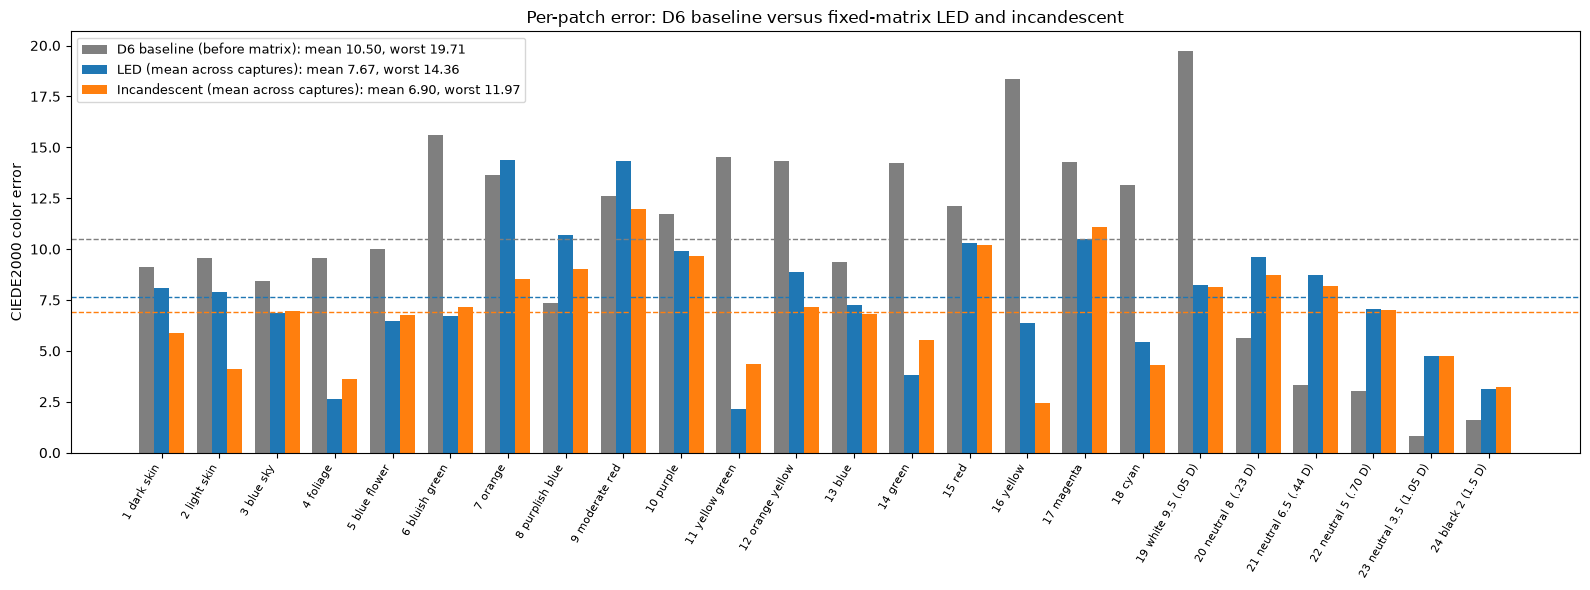

Excluded from all summaries: []
D6 baseline (before matrix): mean DE00 10.50, worst 19.71
    Patch 19 (white 9.5 (.05 D)): 19.71
    Patch 16 (yellow): 18.34
    Patch 6 (bluish green): 15.60
LED (mean across captures): mean DE00 7.67, worst 14.36
    Patch 7 (orange): 14.36
    Patch 9 (moderate red): 14.35
    Patch 8 (purplish blue): 10.69
Incandescent (mean across captures): mean DE00 6.90, worst 11.97
    Patch 9 (moderate red): 11.97
    Patch 17 (magenta): 11.07
    Patch 15 (red): 10.21


In [21]:
importlib.reload(utils)
patchNames = list(cc24_data.data.keys())  # Same order as t_XYZ and OpenCV's MCC24 model

overheadCaptures = D7fit
ledCaptures = D11Results["captures"]
incandescentCaptures = D12Results["captures"]
if not ledCaptures or not incandescentCaptures:
    raise ValueError("Run D11 and D12 before plotting the illuminant comparison")

statsMask = np.asarray(D7fit["fitMask"], dtype=bool).copy()
for capture in ledCaptures + incandescentCaptures:
    statsMask &= capture["comparisonMask"]

conditions = {
    "D6 baseline (before matrix)": np.asarray(baseline["deltaE"]),
    # "Overhead (mean across captures)": np.mean([r["deltaE"] for r in overheadCaptures], axis=0),
    "LED (mean across captures)": np.mean([r["deltaE"] for r in ledCaptures], axis=0),
    "Incandescent (mean across captures)": np.mean(
        [r["deltaE"] for r in incandescentCaptures], axis=0
    ),
}
illuminantSummary = {
    label: utils.summarize_delta_e(values, patchNames, mask=statsMask)
    for label, values in conditions.items()
}

fig, ax = plt.subplots(figsize=(16, 6))
positions = np.arange(len(patchNames))
barWidth = 0.26
colors = ("tab:gray", "tab:blue", "tab:orange")
for index, ((label, values), color) in enumerate(zip(conditions.items(), colors)):
    stats = illuminantSummary[label]
    bars = ax.bar(
        positions + (index - 1) * barWidth, values, width=barWidth, color=color,
        label=f"{label}: mean {stats['meanDeltaE']:.2f}, worst {stats['maxDeltaE']:.2f}",
    )
    for bar, isUsed in zip(bars, statsMask):
        if not isUsed:
            bar.set_hatch("//")
            bar.set_alpha(0.4)
    ax.axhline(stats["meanDeltaE"], color=color, linestyle="--", linewidth=1)

tickLabels = [
    f"{i + 1} {name}" + ("" if statsMask[i] else " (excluded)")
    for i, name in enumerate(patchNames)
]
ax.set_xticks(positions, tickLabels, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("CIEDE2000 color error")
ax.set_title("Per-patch error: D6 baseline versus fixed-matrix LED and incandescent")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig("images/d12.png", dpi=200, bbox_inches="tight")
plt.show()

print("Excluded from all summaries:", np.flatnonzero(~statsMask) + 1)
for label, stats in illuminantSummary.items():
    print(f"{label}: mean DE00 {stats['meanDeltaE']:.2f}, worst {stats['maxDeltaE']:.2f}")
    for patchNumber, name, value in stats["worstPatches"]:
        print(f"    Patch {patchNumber} ({name}): {value:.2f}")

### D13